In [2]:
import matplotlib.pyplot as plt
import json
import os
import numpy as np

In [22]:
for V in [.01, .1, 1]:
    for n_m in range(3, 8):
        path = f'results/Yolo/Li2024-WithoutCapacityConstraints-V={V}/n_m={n_m}-max_d=3000/C_avg=0.005-R_avg=8'
        folders = sorted([int(f.split('=')[1]) for f in os.listdir(path) if os.path.exists(f'{path}/{f}/t=299.json')])
        diff = set(range(22)) - set(folders)  
        print(V, '\t', n_m, '\t', diff)
    print()

0.01 	 3 	 {2, 3, 10, 12, 14}
0.01 	 4 	 set()
0.01 	 5 	 set()
0.01 	 6 	 set()
0.01 	 7 	 set()

0.1 	 3 	 {2, 3, 4, 8, 10, 12, 14}
0.1 	 4 	 {4, 12}
0.1 	 5 	 set()
0.1 	 6 	 set()
0.1 	 7 	 set()

1 	 3 	 {10, 2, 3}
1 	 4 	 set()
1 	 5 	 set()
1 	 6 	 set()
1 	 7 	 set()



In [26]:
list(set(range(22)) - ({2, 3, 10, 12, 14}|{2, 3, 4, 8, 10, 12, 14}|{4, 12}|{10, 2, 3}))

[0, 1, 5, 6, 7, 9, 11, 13, 15, 16, 17, 18, 19, 20, 21]

In [12]:
d = dict()
for V in [.001]:
    d[V] = dict()
    for n_m in range(3, 8):
        d[V][n_m] = dict()
        for seed in range(20):
            path = f"results/Yolo/Li2024-WithoutCapacityConstraints-V={V}/n_m={n_m}-max_d=3000/C_avg=0.005-R_avg=8/id={seed}"
            for fname in sorted(os.listdir(path))[1:]:
                with open(os.path.join(path, fname), 'r') as f:
                    data = json.load(f)
                model_status = data['model_status']
                if data['arrivals'] == np.sum(data['throughput']): 
                    d[V][n_m]['all_executed'] = d[V][n_m].get('all_executed', 0) + 1
                else:
                    d[V][n_m]['not_all_executed'] = d[V][n_m].get('not_all_executed', 0) + 1
                d[V][n_m][model_status] = d[V][n_m].get(model_status, 0) + 1

FileNotFoundError: [Errno 2] No such file or directory: 'results/Yolo/Li2024-WithoutCapacityConstraints-V=0.001/n_m=3-max_d=3000/C_avg=0.005-R_avg=8/id=0'

In [9]:
for V in d:
    print(f"V = {V}")
    for n_n in d[V]:
        print(f"\tn_n = {n_n}")
        for model_status in sorted(d[V][n_n]):
            print(f"\t\t{model_status}: {d[V][n_n][model_status]}")

V = 0.001
	n_n = 3
		Optimal: 5941
		all_executed: 2576
		not_all_executed: 3365
	n_n = 4
		Optimal: 5993
		all_executed: 2605
		not_all_executed: 3388
	n_n = 5
		Optimal: 5986
		all_executed: 2785
		not_all_executed: 3201
	n_n = 6
		Optimal: 5988
		all_executed: 2998
		not_all_executed: 2990
	n_n = 7
		Optimal: 5965
		all_executed: 3251
		not_all_executed: 2714


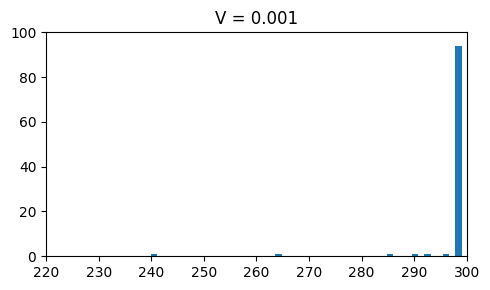

In [10]:
lasts = list()
for n_m in range(3, 8):
    for seed in range(20):
        path = f"results/Yolo/Li2024-WithoutCapacityConstraints-V={.001}/n_m={n_m}-max_d=3000/C_avg=0.005-R_avg=8/id={seed}"
        files = os.listdir(path)
        files.remove('config.json')
        last = int(sorted(files, key=lambda x: int(x.split('=')[1].split('.')[0]))[-1].split('=')[1].split('.')[0])
        if last < 200: print(path)
        lasts.append(last)
plt.figure(figsize=(5, 3))
plt.hist(lasts, bins=50)
plt.xlim((220, 300))
plt.ylim((0, 100))
plt.title(f'V = {V}')
plt.tight_layout()
plt.show()
plt.close()

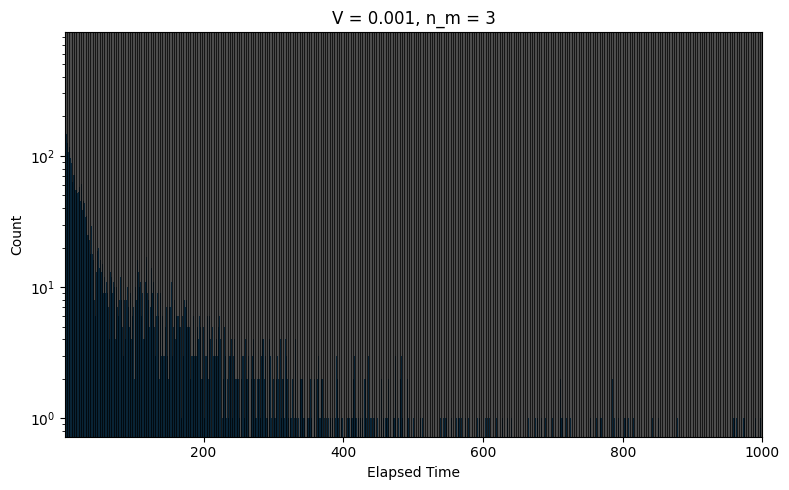

In [17]:
bins = np.linspace(0, 1e3, 1000)

for V, ax in zip([.001], axes):
    for n_m in range(3, 8):
        all_elapsed_times = list()
        for seed in range(20):
            path = f"results/Yolo/Li2024-WithoutCapacityConstraints-V={V}/n_m={n_m}-max_d=3000/C_avg=0.005-R_avg=8/id={seed}"
            files = os.listdir(path)
            files.remove('config.json')
            for file in files:
                with open(os.path.join(path, file), 'r') as f:
                    elapsed_time = json.load(f)["elapsed_time"]
                if elapsed_time < 1e3:
                    all_elapsed_times.append(elapsed_time)
        fig, ax = plt.subplots(figsize=(8, 5))
        counts, bins, patches = ax.hist(all_elapsed_times, bins=bins, log=True)
        ax.set_yscale('log')
        # ax.set_xscale('log')
        ax.set_title(f'V = {V}, n_m = {n_m}')
        ax.set_xlim((1, 1e3))
        ax.set_xlabel('Elapsed Time')
        ax.set_ylabel('Count')
        for edge in bins:
            ax.axvline(edge, color='black', linestyle='-', linewidth=0.5)
        fig.tight_layout()
        plt.show()
        plt.close(fig)
        break
    break